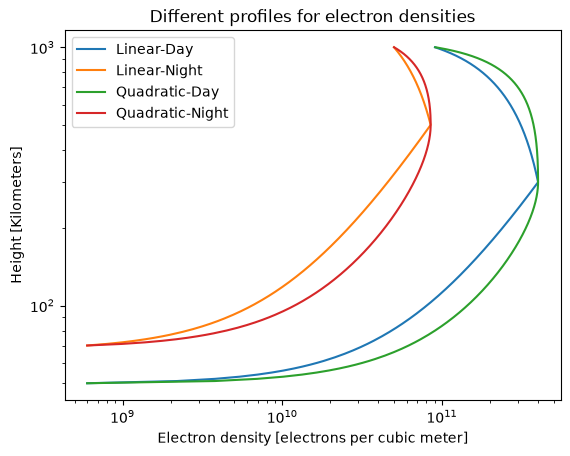

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patch
import scipy.optimize as optimize

# Electron density will change depending of daytime or nighttime

# Linear refraction index

def elec_dens_linear_day(r):
    '''Linear model for electron density distribution in Ionosphere'''
    if (r < 301):
        a = (4e11 - 6e8)/(300 - 50)
        b = 6e8 - a*50
        return a*r + b
    
    else:
        a = (9e10-4e11)/(1000-300)
        b = 9e10 - a*1000
        return a*r + b

def elec_dens_linear_night(r):
    '''Linear model for electron density distribution in Ionosphere at night'''
    if (r < 501):
        a = (8.5e10 - 6e8)/(500 - 70)
        b = 6e8 - a*70
        return a*r + b
    
    else:
        a = (5e10-8.5e10)/(1000-500)
        b = 8.5e10 - a*500
        return a*r + b
    
def elec_dens_quadratic_day(r):
    '''Second order polynomial function approximation for Ionesphere's electro density'''
    if (r < 301):
        x = 50.
        y = 6.e8
        xmax = 300 # Maximum electron density at 300 km
        ymax = 4.e11 # Maximum density during day
        # having a and c in func of b, using an extra point we can get b. The expression is
        b = (y - ymax)/(-1*x*x/(2.*xmax) + x - xmax/2)  
        c = ymax - b*xmax/2 # for condition given to a b has be this
        a = -1.*b/(2.*xmax) # condition to get the max in this point
        return a*r*r + b*r + c
    else :
        x = 1000.
        y = 9.e10
        xmax = 300 # Maximum electron density at 300 km
        ymax = 4.e11 # Maximum density during day
        # having a and c in func of b, using an extra point we can get b. The expression is
        b = (y - ymax)/(-1*x*x/(2.*xmax) + x - xmax/2)  
        c = ymax - b*xmax/2 # for condition given to a b has be this
        a = -1.*b/(2.*xmax) # condition to get the max in this point
        return a*r*r + b*r + c

def elec_dens_quadratic_night(r):
    '''Second order polynomial function approximation for Ionesphere's 
    electro density at night'''
    if (r < 501 ):
        x = 70.
        y = 6.e8
        xmax = 500 # Maximum electron density at 500 km
        ymax = 8.5e10 # Maximum density during night
        b = (y - ymax)/(-1*x*x/(2.*xmax) + x - xmax/2)
        c = ymax - b*xmax/2
        a = -1.*b/(2.*xmax)
        return a*r*r + b*r + c
    else :
        x = 1000.
        y = 5.e10
        xmax = 500 # Maximum electron density at 300 km
        ymax = 8.5e10 # Maximum density during day
        # having a and c in func of b, using an extra point we can get b. The expression is
        b = (y - ymax)/(-1*x*x/(2.*xmax) + x - xmax/2)  
        c = ymax - b*xmax/2 # for condition given to a b has be this
        a = -1.*b/(2.*xmax) # condition to get the max in this point
        return a*r*r + b*r + c


vacuum_permittivity = 8.854e-12 # Permittivity of free space in Faradays over meters
e_charge = -1.602e-19 # Electron charge in Coulombs
e_mass = 9.10938356e-31 # Electron mass in Kilograms

elec_dens_ld = []

for i in range(50,1000,1):
    elec_dens_ld.append(elec_dens_linear_day(i))
    
elec_dens_ln = []

for i in range(70,1000,1):
    elec_dens_ln.append(elec_dens_linear_night(i))


elec_dens_pd = []

for i in range(50,1000,1):
    elec_dens_pd.append(elec_dens_quadratic_day(i))
    
elec_dens_pn = []

for i in range(70,1000,1):
    elec_dens_pn.append(elec_dens_quadratic_night(i))

plt.loglog(elec_dens_ld,np.linspace(50,1000,950))
plt.loglog(elec_dens_ln,np.linspace(70,1000,930))
plt.loglog(elec_dens_pd,np.linspace(50,1000,950))
plt.loglog(elec_dens_pn,np.linspace(70,1000,930))

plt.xlabel("Electron density [electrons per cubic meter]")
plt.ylabel("Height [Kilometers]")
plt.title("Different profiles for electron densities")
plt.legend(["Linear-Day","Linear-Night","Quadratic-Day","Quadratic-Night"])

In [7]:
def ref_index(freq,elec_dens,dens_variation_height = [-1,-1],delta_density = 0):
    total_y = 1200
    N = np.zeros(total_y) # Refraction index

    # First 50 km the refraction index will be 1 (air ref. index approx 1)
    
    for i in range(0,50,1):
        N[i] = 1
    
# The electron density has to be given in units of meters^(-3)
    omega = 2 * np.pi * freq

    for i in range(50,total_y,1):
        if (i>=dens_variation_height[0] and i<=dens_variation_height[1]):
            pl_freq = np.sqrt(((elec_dens(i)+delta_density)*e_charge*e_charge)/(e_mass*vacuum_permittivity))
        else:
            pl_freq = np.sqrt((elec_dens(i)*e_charge*e_charge)/(e_mass*vacuum_permittivity))
        
        if (pl_freq >= omega):
            N[i] = 0
        else:
            N[i] = np.sqrt(1 - (pl_freq/omega)**2)

    return N


for i in range(0,1200,1):
    print("At km ", i ,"ref index is: ",ref_index(1.e8, elec_dens_linear_day,[100,110],5e11)[i])
#print("Refraction index linear night ",ref_index(1.e7, elec_dens_linear_night))
#print("Refraction index quad day ",ref_index(1.e7,elec_dens_quadratic_day))
#print("Refraction index quad night ",ref_index(1.e7,elec_dens_quadratic_night))

At km  0 ref index is:  1.0
At km  1 ref index is:  1.0
At km  2 ref index is:  1.0
At km  3 ref index is:  1.0
At km  4 ref index is:  1.0
At km  5 ref index is:  1.0
At km  6 ref index is:  1.0
At km  7 ref index is:  1.0
At km  8 ref index is:  1.0
At km  9 ref index is:  1.0
At km  10 ref index is:  1.0
At km  11 ref index is:  1.0
At km  12 ref index is:  1.0
At km  13 ref index is:  1.0
At km  14 ref index is:  1.0
At km  15 ref index is:  1.0
At km  16 ref index is:  1.0
At km  17 ref index is:  1.0
At km  18 ref index is:  1.0
At km  19 ref index is:  1.0
At km  20 ref index is:  1.0
At km  21 ref index is:  1.0
At km  22 ref index is:  1.0
At km  23 ref index is:  1.0
At km  24 ref index is:  1.0
At km  25 ref index is:  1.0
At km  26 ref index is:  1.0
At km  27 ref index is:  1.0
At km  28 ref index is:  1.0
At km  29 ref index is:  1.0
At km  30 ref index is:  1.0
At km  31 ref index is:  1.0
At km  32 ref index is:  1.0
At km  33 ref index is:  1.0
At km  34 ref index is: 